In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the original dataset
file_path = "../data/raw/DTS_202_Dataset.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset dimensions:", df.shape)

Dataset loaded successfully!
Dataset dimensions: (395, 33)


In [2]:
# Display the first five records
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
# Display column names, data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [4]:
# Count missing values in each column
missing_values = df.isnull().sum()

print(missing_values)

print("\nTotal missing values:", missing_values.sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total missing values: 0


In [5]:
# Generate descriptive statistics for numerical columns
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [6]:
# Check for duplicate records
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


In [7]:
# Function to calculate IQR outlier boundaries
def check_outliers(column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\nFeature: {column}")
    print(f"Q1: {Q1}")
    print(f"Q3: {Q3}")
    print(f"IQR: {IQR}")
    print(f"Lower boundary: {lower_bound}")
    print(f"Upper boundary: {upper_bound}")
    print(f"Potential outliers: {len(outliers)}")

    return outliers


# Investigate absences and final grades
absence_outliers = check_outliers("absences")
grade_outliers = check_outliers("G3")


Feature: absences
Q1: 0.0
Q3: 8.0
IQR: 8.0
Lower boundary: -12.0
Upper boundary: 20.0
Potential outliers: 15

Feature: G3
Q1: 8.0
Q3: 14.0
IQR: 6.0
Lower boundary: -1.0
Upper boundary: 23.0
Potential outliers: 0


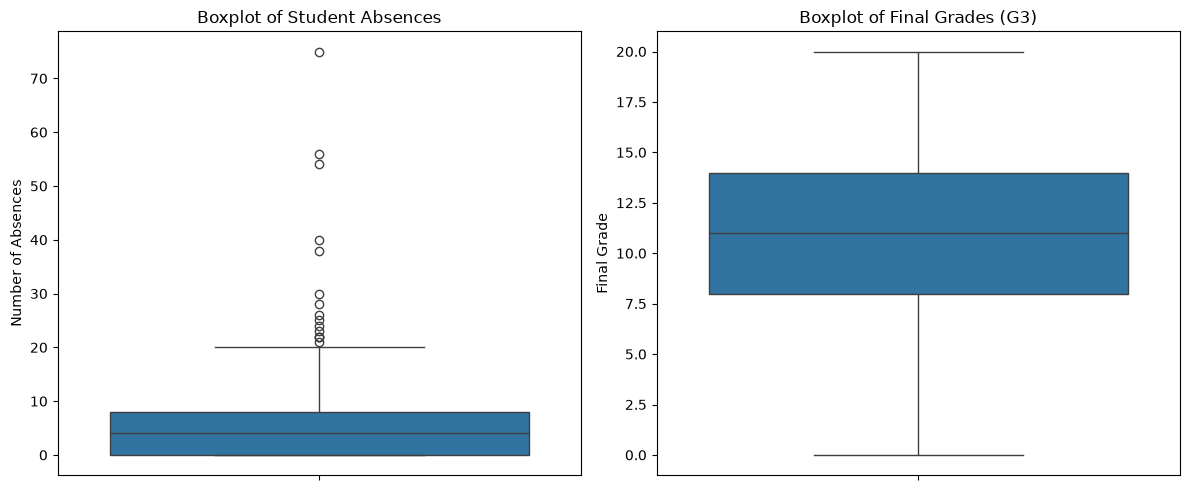

In [8]:
# Visualise potential outliers in absences and G3
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["absences"], ax=axes[0])
axes[0].set_title("Boxplot of Student Absences")
axes[0].set_ylabel("Number of Absences")

sns.boxplot(y=df["G3"], ax=axes[1])
axes[1].set_title("Boxplot of Final Grades (G3)")
axes[1].set_ylabel("Final Grade")

plt.tight_layout()
plt.show()

In [9]:
# Display students with more than 20 absences
print("Students with potential absence outliers:")

display(
    absence_outliers[
        ["age", "studytime", "failures", "absences", "G1", "G2", "G3"]
    ].sort_values("absences", ascending=False)
)

Students with potential absence outliers:


,age,studytime,failures,absences,G1,G2,G3
276,18,2,0,75,10,9,9
183,17,2,0,56,9,9,8
74,16,2,0,54,11,12,11
315,19,3,1,40,13,11,11
307,19,1,1,38,8,9,8
280,17,1,0,30,8,8,8
205,17,3,1,28,10,9,9
103,15,2,0,26,7,6,6
40,16,2,1,25,7,10,11
198,17,1,1,24,18,18,18


### Outlier Detection and Handling

The Interquartile Range (IQR) method was used to
identify potential outliers in the absences and G3
(final grade) columns.

The analysis identified 15 potential outliers in
absences, with values exceeding the upper boundary
of 20. No outliers were detected in G3.

The flagged absence records were inspected. Since
there was insufficient evidence to classify these
values as errors, all 15 records were retained.
No outlier removal or capping was performed.

In [3]:
# Create the Pass/Fail target variable
df["Pass_Fail"] = np.where(df["G3"] >= 10, "Pass", "Fail")

# Display the number of students in each category
print("Pass/Fail Distribution:")
print(df["Pass_Fail"].value_counts())

# Calculate percentages
print("\nPass/Fail Percentage:")
print(df["Pass_Fail"].value_counts(normalize=True) * 100)

Pass/Fail Distribution:
Pass_Fail
Pass    265
Fail    130
Name: count, dtype: int64

Pass/Fail Percentage:
Pass_Fail
Pass    67.088608
Fail    32.911392
Name: proportion, dtype: float64


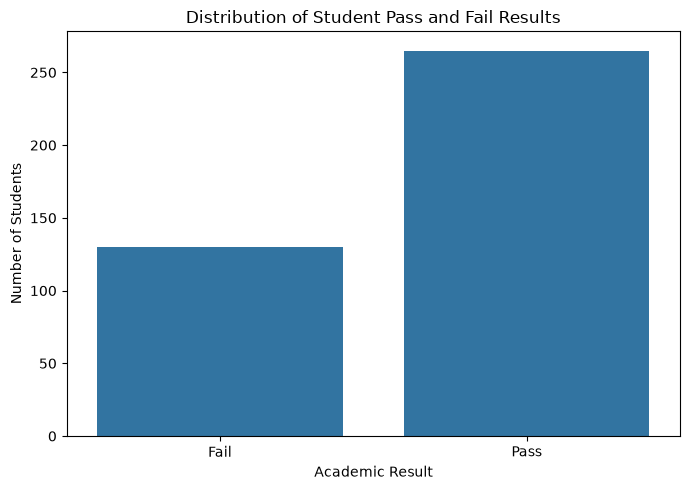

In [4]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Pass_Fail")

plt.title("Distribution of Student Pass and Fail Results")
plt.xlabel("Academic Result")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

Pass rate by study time:
studytime
1    64.761905
2    64.646465
3    75.384615
4    74.074074
Name: Pass_Fail, dtype: float64


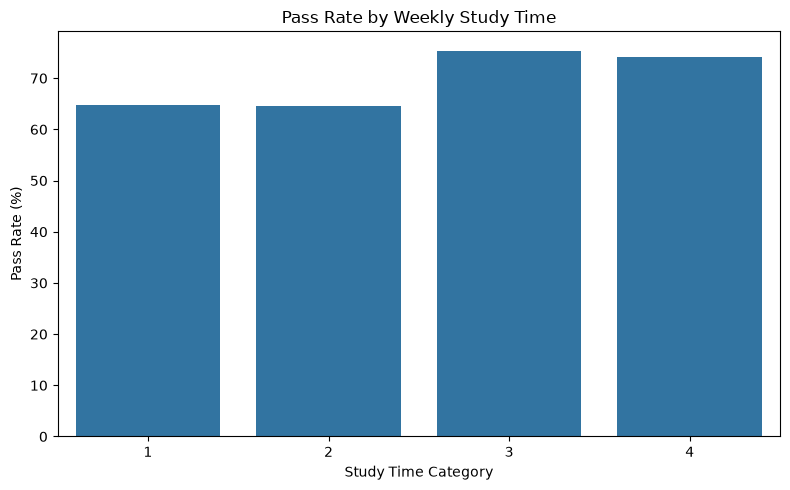

In [5]:
# Calculate pass rates for each study-time category
study_pass_rate = (
    df.groupby("studytime")["Pass_Fail"]
    .apply(lambda x: (x == "Pass").mean() * 100)
)

print("Pass rate by study time:")
print(study_pass_rate)

# Visualise the results
plt.figure(figsize=(8, 5))

sns.barplot(x=study_pass_rate.index, y=study_pass_rate.values)

plt.title("Pass Rate by Weekly Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Pass Rate (%)")

plt.tight_layout()
plt.show()

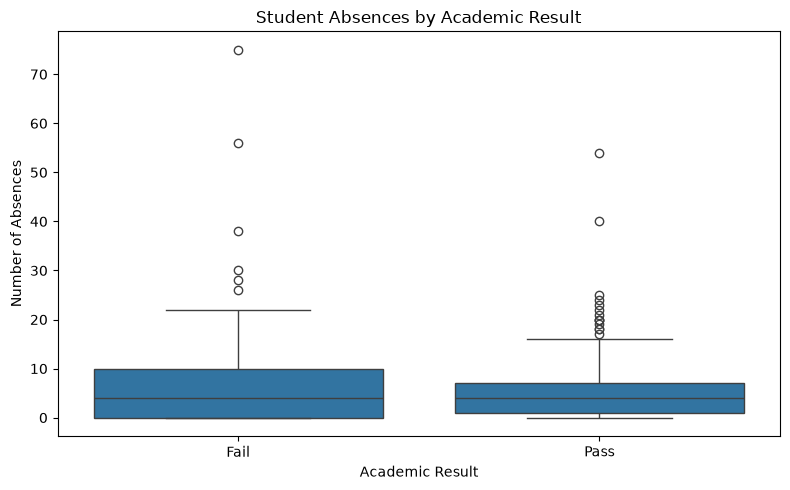

In [6]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Pass_Fail", y="absences")

plt.title("Student Absences by Academic Result")
plt.xlabel("Academic Result")
plt.ylabel("Number of Absences")

plt.tight_layout()
plt.show()

In [7]:
# Calculate student counts and pass rates by study time
study_analysis = df.groupby("studytime").agg(
    Total_Students=("Pass_Fail", "size"),
    Students_Passed=("Pass_Fail", lambda x: (x == "Pass").sum()),
    Students_Failed=("Pass_Fail", lambda x: (x == "Fail").sum())
)

study_analysis["Pass_Rate (%)"] = (
    study_analysis["Students_Passed"] /
    study_analysis["Total_Students"] * 100
)

display(study_analysis.round(2))

,Total_Students,Students_Passed,Students_Failed,Pass_Rate (%)
studytime,,,,
1,105,68,37,64.76
2,198,128,70,64.65
3,65,49,16,75.38
4,27,20,7,74.07


In [8]:
# Inspect unique values in categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "str"]
).columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(sorted(df[column].dropna().unique()))


school:
['GP', 'MS']

sex:
['F', 'M']

address:
['R', 'U']

famsize:
['GT3', 'LE3']

Pstatus:
['A', 'T']

Mjob:
['at_home', 'health', 'other', 'services', 'teacher']

Fjob:
['at_home', 'health', 'other', 'services', 'teacher']

reason:
['course', 'home', 'other', 'reputation']

guardian:
['father', 'mother', 'other']

schoolsup:
['no', 'yes']

famsup:
['no', 'yes']

paid:
['no', 'yes']

activities:
['no', 'yes']

nursery:
['no', 'yes']

higher:
['no', 'yes']

internet:
['no', 'yes']

romantic:
['no', 'yes']

Pass_Fail:
['Fail', 'Pass']


In [9]:
# Create a compact summary of categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "str"]
).columns.drop("Pass_Fail", errors="ignore")

category_summary = pd.DataFrame({
    "Column": categorical_columns,
    "Unique Values": [
        ", ".join(sorted(df[col].dropna().unique()))
        for col in categorical_columns
    ],
    "Number of Categories": [
        df[col].nunique()
        for col in categorical_columns
    ]
})

display(category_summary)

,Column,Unique Values,Number of Categories
0,school,"GP, MS",2
1,sex,"F, M",2
2,address,"R, U",2
3,famsize,"GT3, LE3",2
4,Pstatus,"A, T",2
5,Mjob,"at_home, health, other, services, teacher",5
6,Fjob,"at_home, health, other, services, teacher",5
7,reason,"course, home, other, reputation",4
8,guardian,"father, mother, other",3
9,schoolsup,"no, yes",2


## Exploratory Data Analysis — Summary

The dataset contains 395 student records and 33
original features, comprising 16 numerical and
17 categorical columns.

The initial investigation identified no missing
values or duplicate records.

The IQR method identified 15 potential outliers
in the absences column. These records were
investigated and retained because there was
insufficient evidence that they were erroneous.
No outliers were detected in the G3 column.

A Pass/Fail target was created using G3 >= 10
as the passing threshold. This was a project-defined
assumption because the assessment brief did not
specify a numerical threshold.

The resulting dataset contained 265 passing
students (67.09%) and 130 failing students (32.91%).

The study-time analysis showed higher pass rates
among students in study-time categories 3 and 4
compared with categories 1 and 2.

The analysis also showed that absence distributions
varied between the Pass and Fail groups.